# Session 7 — Geographic Concentration
### FAA National Wildlife Strike Database

**The question:** where are strikes *reported* — and can this dataset say where strikes are *likely*?

**The answer, up front:** this dataset describes the geography of **reports**. By itself it cannot compare how
likely strikes are in different places, because it contains strike reports but no count of flights to divide
them by: a busy airport and an airport with a high strike rate look identical here. Everything below is
written to that limit — a rank is a rank of report counts, and no place is described as dangerous or safe.

What each section does:

0. What the geographic fields cover, and what they leave out.
1. Raw concentration: which states and airports have the most reports, stated as what it is.
2. The volume confound made concrete, with real outside traffic numbers for four airports.
3. A composition question that sidesteps volume: what gets struck and how severe it is, as shares *within*
   each state.
4. A spatial view, and what the coordinates actually are.
5. What it would take to answer the volume question properly (future work, not attempted).

Two corrections to earlier work turned up on the way here, both documented where they were fixed: notebook
01's claim that `UNKNOWN` airports fully explain a missing `STATE` was wrong by 78 rows, and notebook 04's
`SIZE` analysis had been counting non-bird animals as "bird size" (section 3 below uses birds only).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 80)
pd.set_option('display.width', 160)

df = pd.read_pickle('../data/processed/strikes_clean.pkl.gz')
print('shape:', df.shape)
print('NUM_SEEN dtype:', df['NUM_SEEN'].dtype, '(the cleaned file, not the raw CSV)')


shape: (354144, 101)
NUM_SEEN dtype: category (the cleaned file, not the raw CSV)


## 0. What the geographic fields cover

Before ranking anything: which rows have a place at all? `AIRPORT_ID` is the unit; `STATE`, `LATITUDE`,
`LONGITUDE`, and `FAAREGION` come with it. Four codes are placeholders, not real airports — `ZZZZ`
(`UNKNOWN`), `RIGG` (oil rig), `PVT` (private air strip), and `H2O` (remote water) — and are excluded from
every ranking below. 2026 is excluded throughout, as in notebooks 03–04 (a partial year with reporting lag).

In [2]:
US_STATES = ('AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY '
             'NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC').split()
PLACEHOLDER = ['ZZZZ', 'RIGG', 'PVT', 'H2O']   # UNKNOWN airport, oil rig, private air strip, remote water

d = df[df['INCIDENT_YEAR'] <= 2025].copy()     # 2026 excluded, as in notebooks 03-04: a partial year with reporting lag
placeholder = d['AIRPORT_ID'].isin(PLACEHOLDER)
no_id = d['AIRPORT_ID'].isna()
real = ~placeholder & ~no_id
print(f'rows, 1990-2025: {len(d):,}')
yc = d.groupby('INCIDENT_YEAR').size()
print(f'reports per year: 1990 = {yc[1990]:,}, 2025 = {yc[2025]:,} ({yc[2025] / yc[1990]:.1f}x)')
print(f'  at a real airport                       : {real.sum():>8,} ({real.mean() * 100:.1f}%)')
print(f'  placeholder "airport"                   : {placeholder.sum():>8,} ({placeholder.mean() * 100:.1f}%)')
print(f'  no AIRPORT_ID at all                    : {no_id.sum():>8,}')
print()
print(d.loc[placeholder, ['AIRPORT_ID', 'AIRPORT']].value_counts().to_string())

zz = d['AIRPORT_ID'] == 'ZZZZ'
er = d['PHASE_OF_FLIGHT'] == 'En Route'
print()
print(f'En Route rows: {er.sum():,} ({er.mean() * 100:.1f}% of all rows); AIRPORT_ID on those rows: '
      f'{d.loc[er, "AIRPORT_ID"].value_counts().to_dict()}')
print(f'  ENROUTE_STATE is filled on {d.loc[er, "ENROUTE_STATE"].notna().mean() * 100:.1f}% of them (the location of an en-route strike)')
print(f'UNKNOWN-airport (ZZZZ) rows: {zz.sum():,}; of those, En Route: {(zz & er).sum():,}; '
      f'with no PHASE_OF_FLIGHT at all: {(zz & d["PHASE_OF_FLIGHT"].isna()).sum():,}')

print()
grp = pd.Series(np.where(d['STATE'].isna(), 'no STATE',
                np.where(d['STATE'].isin(US_STATES), '50 states + DC', 'territories / Canada / foreign')), index=d.index)
print(grp.value_counts().to_string())
print('STATE codes outside the 50 states + DC:', d.loc[d['STATE'].notna() & ~d['STATE'].isin(US_STATES), 'STATE'].value_counts().to_dict())


rows, 1990-2025: 343,564
reports per year: 1990 = 2,120, 2025 = 24,459 (11.5x)
  at a real airport                       :  297,516 (86.6%)
  placeholder "airport"                   :   46,047 (13.4%)
  no AIRPORT_ID at all                    :        1

AIRPORT_ID  AIRPORT          
ZZZZ        UNKNOWN              45970
RIGG        OIL RIG                 51
PVT         PRIVATE AIR STRIP       19
H2O         REMOTE_WATER             7

En Route rows: 6,255 (1.8% of all rows); AIRPORT_ID on those rows: {'ZZZZ': 6255}
  ENROUTE_STATE is filled on 90.3% of them (the location of an en-route strike)
UNKNOWN-airport (ZZZZ) rows: 45,970; of those, En Route: 6,255; with no PHASE_OF_FLIGHT at all: 39,103

50 states + DC                    289905
no STATE                           46048
territories / Canada / foreign      7611
STATE codes outside the 50 states + DC: {'FN': 5204, 'PR': 768, 'VI': 396, 'GU': 336, 'MP': 238, 'ON': 189, 'BC': 130, 'UM': 118, 'QC': 72, 'AS': 59, 'AB': 57, 'MB': 16,

Three things to carry forward:

- **13.4% of rows have no real airport** (46,047 of 343,564), and so no state, coordinates, or region. Almost
  all of them (45,970) are the `UNKNOWN` placeholder `ZZZZ`; the other 77 are an oil rig, private air strips,
  and remote water, which genuinely have no fixed location. This is the set whose size notebook 01 originally
  misstated; see the correction in its Section 2.
- **En-route strikes are invisible to any airport or state view.** All 6,255 en-route rows (1.8% of reports)
  sit in the `ZZZZ` group; their location is recorded in `ENROUTE_STATE` instead (filled on 90.3% of them),
  which this notebook does not use. A further 39,103 `ZZZZ` rows have no `PHASE_OF_FLIGHT` at all, so for
  most unplaced rows nothing says where the aircraft was.
- **"State" means the airport's state**, and 7,611 rows are in territories, Canadian provinces, or foreign
  airports (`FN`, 5,204, is the largest group). The state analyses below cover the 50 states and DC only.

## 1. Raw concentration — reports, not risk

**What follows ranks *reported* strikes, not how likely a strike is.** This dataset has no flight-operations
or passenger-enplanement data to divide by, so a state or airport can lead a raw count because it has more
wildlife, more aircraft movements, more diligent reporting, or any mix of the three — and nothing here can
tell those apart. Section 2 shows with real numbers how much that matters.

In [3]:
state_counts = d[d['STATE'].isin(US_STATES)].groupby('STATE').size().sort_values(ascending=False)
airport_counts = (d[real].groupby(['AIRPORT_ID', 'AIRPORT', 'STATE']).size()
                  .sort_values(ascending=False).rename('reports').reset_index())

print('TOP 15 STATES by number of reports, 1990-2025 (a count of reports, not a ranking of risk)')
top_states = state_counts.head(15).to_frame('reports')
top_states['% of all state-coded rows'] = (top_states['reports'] / state_counts.sum() * 100).round(1)
print(top_states.to_string())
print()
print('TOP 15 AIRPORTS by number of reports, 1990-2025 (placeholders excluded)')
top_ap = airport_counts.head(15).copy()
top_ap['% of real-airport rows'] = (top_ap['reports'] / real.sum() * 100).round(2)
print(top_ap.to_string(index=False))

per_ap = airport_counts['reports']
print()
print(f'distinct real airports: {len(per_ap):,}')
print(f'top 10 airports hold {per_ap.head(10).sum() / real.sum() * 100:.1f}% of real-airport rows; top 50 hold {per_ap.head(50).sum() / real.sum() * 100:.1f}%')
print(f'median reports per airport: {int(per_ap.median())}; airports with fewer than 10 reports: {(per_ap < 10).sum():,} ({(per_ap < 10).mean() * 100:.1f}%)')
print(f'airports with 1,000+ reports: {(per_ap >= 1000).sum()}')
print(f'top 5 states hold {state_counts.head(5).sum() / state_counts.sum() * 100:.1f}% of state-coded rows')


TOP 15 STATES by number of reports, 1990-2025 (a count of reports, not a ranking of risk)
       reports  % of all state-coded rows
STATE                                    
TX       30743                       10.6
FL       25099                        8.7
CA       24115                        8.3
NY       16111                        5.6
CO       15002                        5.2
IL       13819                        4.8
TN       10453                        3.6
OH        9119                        3.1
PA        9071                        3.1
MI        8476                        2.9
NJ        8029                        2.8
KY        7851                        2.7
MO        7406                        2.6
NC        7277                        2.5
GA        6630                        2.3

TOP 15 AIRPORTS by number of reports, 1990-2025 (placeholders excluded)
AIRPORT_ID                                    AIRPORT STATE  reports  % of real-airport rows
      KDEN                    

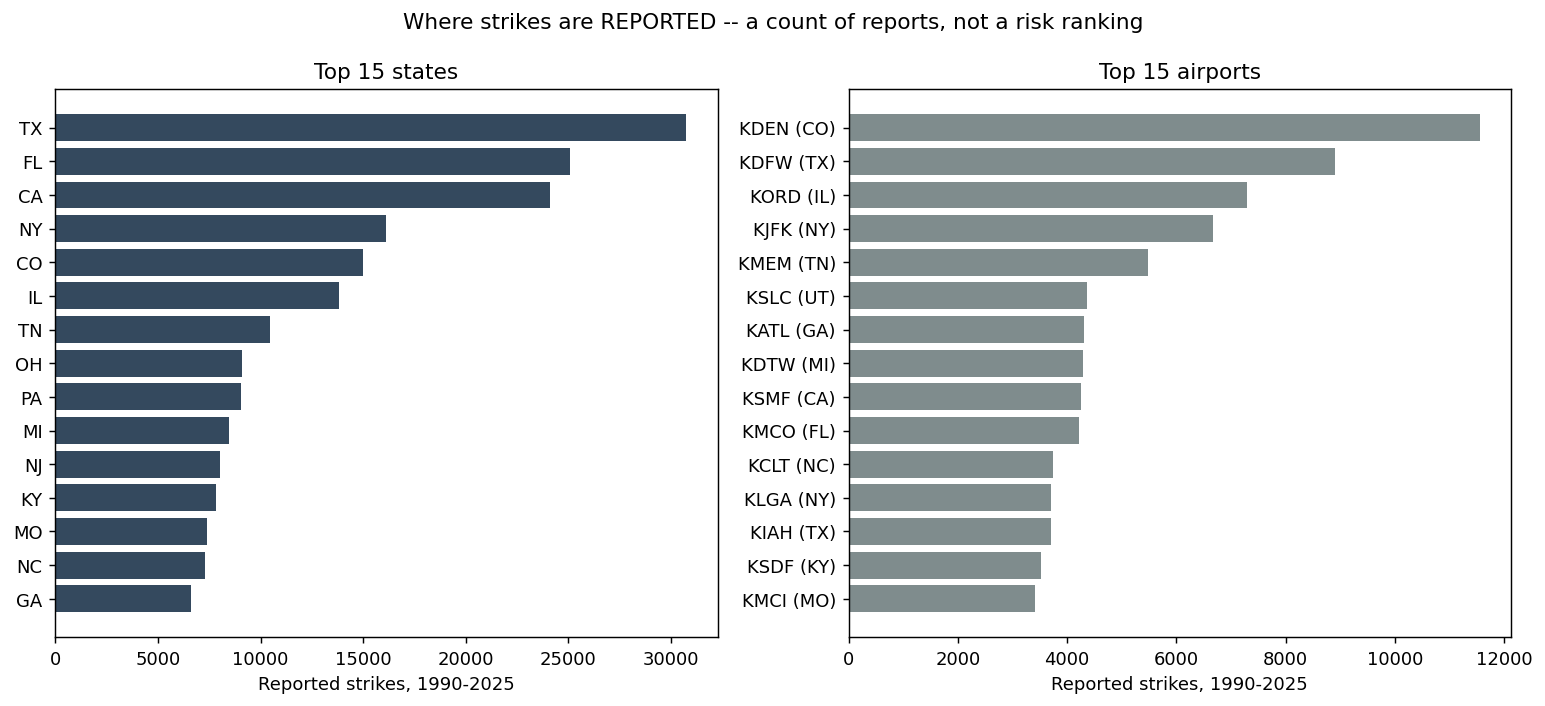

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
ts = state_counts.head(15)[::-1]
axes[0].barh(ts.index, ts.values, color='#34495e')
axes[0].set_title('Top 15 states')
axes[0].set_xlabel('Reported strikes, 1990-2025')
ta = airport_counts.head(15)[::-1]
axes[1].barh([f'{a} ({s})' for a, s in zip(ta['AIRPORT_ID'], ta['STATE'])], ta['reports'], color='#7f8c8d')
axes[1].set_title('Top 15 airports')
axes[1].set_xlabel('Reported strikes, 1990-2025')
fig.suptitle('Where strikes are REPORTED -- a count of reports, not a risk ranking', fontsize=12)
fig.tight_layout()


Texas, Florida, California, New York and Colorado lead the state counts and together hold 38.3% of state-coded
rows; Denver, Dallas-Fort Worth, Chicago O'Hare, New York JFK and Memphis lead the airport counts. That reads
like a list of big hubs with a few surprises (Memphis, Salt Lake City, Sacramento) — a resemblance that is the
whole point of section 2, not a finding.

What the raw picture does establish, as facts about the *distribution of reports*:

- **Very concentrated at the top, very thin at the bottom.** The top 10 of 2,772 airports hold 20.6% of the
  rows at real airports and the top 50 hold 55.4%, while the median airport has 3 reports and 1,918 airports
  (69.2%) have fewer than 10. Only 68 airports have 1,000 or more.
- **The counts are cumulative over 1990-2025**, a span over which annual report volume grew more than tenfold
  (2,120 reports in 1990, 24,459 in 2025), so recent years carry far more weight than early ones.
- **They leave out the 13.4% of rows with no real airport** (section 0).

## 2. The volume confound, made concrete

The raw rankings set up a question this dataset can't answer by itself: how much of "where reports are" is
simply "where flights are"? A real number helps more than a caveat, so here are four airports with outside
traffic data.

**Source and what it is.** Operations — landings plus takeoffs, counted by controllers at towered airports —
come from the FAA's Terminal Area Forecast (TAF) Summary FY2025-FY2055, Table S-4, "Operations at Large Hub
Airports" (in thousands, fiscal years 2022-2025). Every transcribed value was re-checked against the source.
The TAF is on a **U.S. government fiscal-year basis (October-September)**, so strike reports are assigned to the
same fiscal years by `INCIDENT_DATE` rather than by calendar year.

**Why these four.** They are an illustration chosen to make a point, not a sample or a ranking. Chicago
O'Hare and Detroit are both large hubs in the same FAA region (the cell below prints it), and the order of
their raw counts flips once traffic is considered. Denver and Atlanta are included for contrast, including one
case where the adjustment does *not* flip the order.

In [5]:
# Operations (landings + takeoffs) at four large-hub airports, in THOUSANDS, by U.S. government fiscal year
# (October-September). Transcribed from the FAA Terminal Area Forecast (TAF) Summary FY2025-FY2055,
# Table S-4 "Operations at Large Hub Airports" (https://taf.faa.gov/Downloads/TAFSummaryFY2025-FY2055.pdf),
# and re-checked against the source after transcription. Four airports only -- an illustration, not a join.
TAF_OPS_K = {
    'KORD': {2022: 727, 2023: 717, 2024: 758, 2025: 835},
    'KATL': {2022: 724, 2023: 763, 2024: 791, 2025: 809},
    'KDEN': {2022: 614, 2023: 647, 2024: 694, 2025: 705},
    'KDTW': {2022: 292, 2023: 285, 2024: 299, 2025: 319},
}
dates = pd.to_datetime(df['INCIDENT_DATE'])
df['FY'] = dates.dt.year + (dates.dt.month >= 10).astype(int)   # fiscal year = the calendar year it ends in

rows = []
for ap, by_fy in TAF_OPS_K.items():
    for fy, ops_k in by_fy.items():
        reports = int(((df['AIRPORT_ID'] == ap) & (df['FY'] == fy)).sum())
        rows.append(dict(airport=ap, FY=fy, reports=reports, ops_k=ops_k,
                         per_10k_ops=reports / (ops_k * 1000) * 10_000))
conf = pd.DataFrame(rows)

fy25 = conf[conf['FY'] == 2025].set_index('airport').drop(columns='FY')
fy25['rank_by_reports'] = fy25['reports'].rank(ascending=False).astype(int)
fy25['rank_by_ops'] = fy25['ops_k'].rank(ascending=False).astype(int)
fy25['rank_by_rate'] = fy25['per_10k_ops'].rank(ascending=False).astype(int)
print('FAA region of each airport:', df[df['AIRPORT_ID'].isin(TAF_OPS_K)].groupby('AIRPORT_ID')['FAAREGION'].first().to_dict())
print('FY2025 (Oct 2024 - Sep 2025): reports in this dataset vs. operations from the FAA TAF')
print(fy25.sort_values('reports', ascending=False).round(2).to_string())


FAA region of each airport: {'KATL': 'ASO', 'KDEN': 'ANM', 'KDTW': 'AGL', 'KORD': 'AGL'}
FY2025 (Oct 2024 - Sep 2025): reports in this dataset vs. operations from the FAA TAF
         reports  ops_k  per_10k_ops  rank_by_reports  rank_by_ops  rank_by_rate
airport                                                                         
KDEN         915    705        12.98                1            3             1
KORD         426    835         5.10                2            1             3
KATL         320    809         3.96                3            2             4
KDTW         303    319         9.50                4            4             2


In [6]:
print('ORD vs DTW, every fiscal year in the TAF table:')
by = {ap: conf[conf['airport'] == ap].set_index('FY') for ap in ['KORD', 'KDTW']}
cmp = pd.DataFrame({
    'ORD_reports': by['KORD']['reports'], 'DTW_reports': by['KDTW']['reports'],
    'ORD_ops_k': by['KORD']['ops_k'], 'DTW_ops_k': by['KDTW']['ops_k'],
    'ORD_per_10k': by['KORD']['per_10k_ops'], 'DTW_per_10k': by['KDTW']['per_10k_ops'],
})
cmp['ORD_has_more_reports'] = cmp['ORD_reports'] > cmp['DTW_reports']
cmp['ORD_has_lower_rate'] = cmp['ORD_per_10k'] < cmp['DTW_per_10k']
cmp['reports_ratio_ORD/DTW'] = cmp['ORD_reports'] / cmp['DTW_reports']
cmp['ops_ratio_ORD/DTW'] = cmp['ORD_ops_k'] / cmp['DTW_ops_k']
cmp['rate_ratio_DTW/ORD'] = cmp['DTW_per_10k'] / cmp['ORD_per_10k']
print(cmp.round(2).to_string())
print()
print('rate per 10,000 operations, all four airports, all four fiscal years:')
print(conf.pivot(index='airport', columns='FY', values='per_10k_ops').round(2).to_string())


ORD vs DTW, every fiscal year in the TAF table:
      ORD_reports  DTW_reports  ORD_ops_k  DTW_ops_k  ORD_per_10k  DTW_per_10k  ORD_has_more_reports  ORD_has_lower_rate  reports_ratio_ORD/DTW  ops_ratio_ORD/DTW  rate_ratio_DTW/ORD
FY                                                                                                                                                                                    
2022          332          259        727        292         4.57         8.87                  True                True                   1.28               2.49                1.94
2023          327          198        717        285         4.56         6.95                  True                True                   1.65               2.52                1.52
2024          511          276        758        299         6.74         9.23                  True                True                   1.85               2.54                1.37
2025          426          303       

In [7]:
# Is a "report" a strike on an identified flight? Share of reports with no flight number / unknown damage status,
# FY2022-FY2025 combined, for the same four airports.
win = df[df['FY'].between(2022, 2025) & df['AIRPORT_ID'].isin(TAF_OPS_K)]
comp = win.groupby('AIRPORT_ID').agg(
    reports=('INDEX_NR', 'size'),
    pct_no_flight_number=('FLT', lambda s: s.isna().mean() * 100),
    pct_damage_status_unknown=('DAMAGE_LEVEL', lambda s: (s == 'Unknown').mean() * 100),
).round(1)
print(comp.to_string())


            reports  pct_no_flight_number  pct_damage_status_unknown
AIRPORT_ID                                                          
KATL           1277                  41.8                       47.8
KDEN           3104                  50.8                       62.3
KDTW           1036                  47.0                       55.6
KORD           1596                  48.3                       58.2


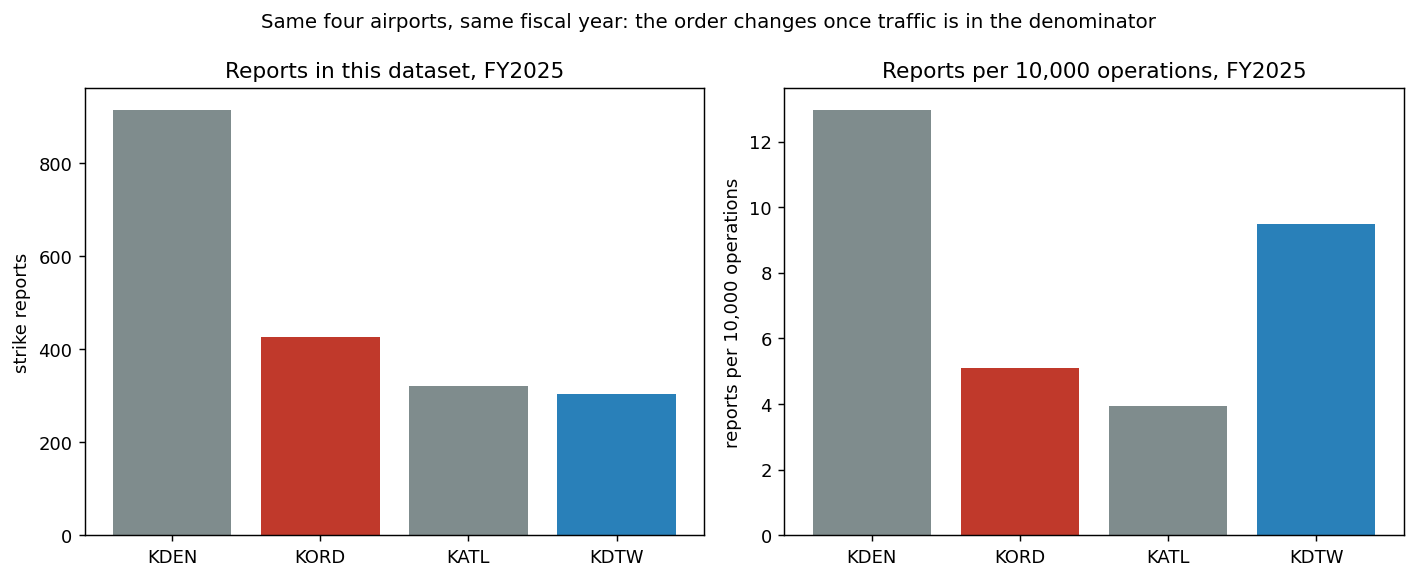

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
order = fy25.sort_values('reports', ascending=False).index.tolist()
colors = {'KDEN': '#7f8c8d', 'KORD': '#c0392b', 'KATL': '#7f8c8d', 'KDTW': '#2980b9'}
axes[0].bar(order, fy25.loc[order, 'reports'], color=[colors[a] for a in order])
axes[0].set_title('Reports in this dataset, FY2025')
axes[0].set_ylabel('strike reports')
axes[1].bar(order, fy25.loc[order, 'per_10k_ops'], color=[colors[a] for a in order])
axes[1].set_title('Reports per 10,000 operations, FY2025')
axes[1].set_ylabel('reports per 10,000 operations')
fig.suptitle('Same four airports, same fiscal year: the order changes once traffic is in the denominator', fontsize=11)
fig.tight_layout()


**The order flips.** In FY2025 Chicago O'Hare has more reports than Detroit (426 vs. 303) but handles about
2.6 times the operations (835,000 vs. 319,000), so per 10,000 operations Detroit's rate (9.50) is nearly
double O'Hare's (5.10). It is not a one-year accident: in each of the four fiscal years O'Hare has more
reports *and* a lower rate, with Detroit's rate between 1.4 and 1.9 times O'Hare's (the rate-ratio column
above). A raw count would have ranked them the opposite way round.

**It doesn't always flip.** Denver leads on raw reports (915) *and* on rate (12.98 per 10,000 operations),
with fewer operations than O'Hare or Atlanta. So adjusting for traffic can reinforce a raw ranking as easily as
reverse one — what it can't do is say *why* Denver's rate is high.

**What the per-operation rate still is not.**

- **A report is not always a strike on an identified flight.** Between 42% and 51% of the reports at these
  four airports in FY2022-FY2025 have no flight number (table above). That doesn't explain the differences
  between the airports — all four sit within a nine-point band — but it means "strike reports" overstates
  "aircraft that hit wildlife".
- **Operations are all operations**: general aviation, air taxi and military as well as the airliners that
  account for most of a hub's traffic, so the denominator isn't the exposure of the aircraft that mostly get
  struck.
- **The rate still mixes the same three things** — wildlife environment, aircraft and runway mix, and how
  diligently reports get filed. It is a better-matched comparison than a raw count, not a measure of risk.
- **Four airports, one pair picked because it flips.** This shows that the raw order can mislead; it does not
  show by how much, or how often, across the other 2,700 airports.
- **FY2025 ended in September 2025** and the dataset runs to August 2026, so the newest year is the one most
  exposed to late filings.

## 3. Composition within each state

A question the volume problem doesn't touch: not *how many* reports a state has, but *what they are like* —
what share involve large birds, what share involve non-bird animals, what share involve damage. Shares within
a state compare like with like however busy the state is. Choices, stated rather than buried:

- **Window: 2013-2024 only** — after species identification stabilised (notebook 04) and before 2025's
  unexplained dip. The completeness of the fields used is in the first table below (size known in 80-94% of
  reports, damage status known in 45-59%).
- **Population: the 50 states and DC.** Territories, Canadian provinces and foreign airports are excluded
  (section 0 gives their size).
- **Three measures.** (1) Non-bird animals as a share of all reports. (2) Large birds as a share of
  known-size *bird* reports. (3) Any damage as a share of reports with a known damage status. Non-birds are
  identified with the FAA species code validated in notebook 04. They are left out of measure (2) because
  `SIZE` is filled in for non-bird animals too (31.9% of the `Large` class, notebook 04); the national
  Large share would otherwise be inflated by deer, coyotes and skunks.
- **Sample floor: 1,000 known-value rows per state** for both the size and damage measures, the same
  discipline as notebook 04's n>=30 floor. The trade-off table below shows the alternatives.

In [9]:
w = df[df['INCIDENT_YEAR'].between(2013, 2024) & df['STATE'].isin(US_STATES)].copy()
w['nonbird'] = w['SPECIES_ID'].str[0].isin(['1', '2'])          # FAA code: mammals, reptiles, amphibians (validated in notebook 04)
w['large'] = (w['SIZE'] == 'Large').where(w['SIZE'].notna() & ~w['nonbird'])   # known-size BIRD reports only
w['any_damage'] = w['DAMAGE_LEVEL'].isin(['M', 'M?', 'S', 'D']).where(w['DAMAGE_LEVEL'] != 'Unknown')
w[['large', 'any_damage']] = w[['large', 'any_damage']].astype('float')
w['no_flight'] = w['FLT'].isna()
w['unidentified'] = w['SPECIES'].str.startswith('Unknown bird')

by_year = w.groupby('INCIDENT_YEAR').agg(
    rows=('INDEX_NR', 'size'),
    size_known=('SIZE', lambda s: s.notna().mean() * 100),
    damage_known=('DAMAGE_LEVEL', lambda s: (s != 'Unknown').mean() * 100)).round(1)
print(f'window 2013-2024, 50 states + DC: {len(w):,} rows')
print(by_year.to_string())
print()
print(f"national: non-bird animals {w['nonbird'].mean() * 100:.2f}% of reports; "
      f"Large share of known-size BIRD reports {w['large'].mean() * 100:.2f}% (n={w['large'].count():,}); "
      f"any-damage share of known-damage reports {w['any_damage'].mean() * 100:.2f}% (n={w['any_damage'].count():,})")


window 2013-2024, 50 states + DC: 156,723 rows
                rows  size_known  damage_known
INCIDENT_YEAR                                 
2013            9681        94.4          56.0
2014           11649        88.2          58.7
2015           11710        89.3          59.1
2016           11520        85.2          57.0
2017           12469        88.0          48.5
2018           13600        86.9          51.5
2019           14361        85.2          49.8
2020           10093        86.7          44.7
2021           13282        83.7          49.1
2022           14354        82.4          51.3
2023           16098        80.4          52.8
2024           17906        80.4          52.7

national: non-bird animals 5.03% of reports; Large share of known-size BIRD reports 4.54% (n=125,851); any-damage share of known-damage reports 7.32% (n=82,289)


In [10]:
g = w.groupby('STATE').agg(
    rows=('INDEX_NR', 'size'), nonbird=('nonbird', 'sum'),
    n_size=('large', 'count'), large=('large', 'sum'),
    n_dmg=('any_damage', 'count'), dmg=('any_damage', 'sum'),
    pct_no_flight=('no_flight', lambda s: s.mean() * 100),
    pct_unidentified=('unidentified', lambda s: s.mean() * 100),
    pct_damage_known=('DAMAGE_LEVEL', lambda s: (s != 'Unknown').mean() * 100),
)
print('how a sample-size floor trades off states against rows (known-value rows per state, both measures):')
for floor in [250, 500, 1000, 2000]:
    ok = (g['n_size'] >= floor) & (g['n_dmg'] >= floor)
    print(f'  floor {floor:>4}: {ok.sum():>2} of {len(g)} states qualify, covering {g.loc[ok, "rows"].sum() / g["rows"].sum() * 100:.1f}% of window rows')
FLOOR = 1000
q = g[(g['n_size'] >= FLOOR) & (g['n_dmg'] >= FLOOR)].copy()
print()
print(f'floor used: {FLOOR} known-value rows for BOTH measures -> {len(q)} states; excluded: {sorted(set(g.index) - set(q.index))}')


how a sample-size floor trades off states against rows (known-value rows per state, both measures):
  floor  250: 46 of 51 states qualify, covering 99.0% of window rows
  floor  500: 35 of 51 states qualify, covering 94.1% of window rows
  floor 1000: 26 of 51 states qualify, covering 85.5% of window rows
  floor 2000: 13 of 51 states qualify, covering 64.0% of window rows

floor used: 1000 known-value rows for BOTH measures -> 26 states; excluded: ['AK', 'AL', 'AR', 'CT', 'DE', 'IA', 'ID', 'KS', 'ME', 'MN', 'MS', 'MT', 'ND', 'NE', 'NH', 'NM', 'NV', 'OK', 'RI', 'SD', 'VA', 'VT', 'WI', 'WV', 'WY']


In [11]:
def wilson(k, n, z=1.96):
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half

MEASURES = [  # name, count column, denominator column, national value
    ('nonbird', 'nonbird', 'rows', w['nonbird'].mean() * 100),
    ('large', 'large', 'n_size', w['large'].mean() * 100),
    ('dmg', 'dmg', 'n_dmg', w['any_damage'].mean() * 100),
]
for name, k, n, nat in MEASURES:
    q[f'{name}_pct'] = q[k] / q[n] * 100
    q[[f'{name}_lo', f'{name}_hi']] = [(lo * 100, hi * 100) for lo, hi in (wilson(a, b) for a, b in zip(q[k], q[n]))]
q = q.sort_values('rows', ascending=False)

print(q[['rows', 'nonbird_pct', 'n_size', 'large_pct', 'n_dmg', 'dmg_pct']].round(1).to_string())
print()
labels = {'nonbird': 'non-bird share of all reports', 'large': 'Large share of known-size bird reports',
          'dmg': 'any-damage share of known-damage reports'}
for name, k, n, nat in MEASURES:
    col, lo, hi = f'{name}_pct', f'{name}_lo', f'{name}_hi'
    above = int((q[lo] > nat).sum()); below = int((q[hi] < nat).sum())
    print(f'{labels[name]}: national {nat:.1f}%; states {q[col].min():.1f}% ({q[col].idxmin()}) to {q[col].max():.1f}% ({q[col].idxmax()}); '
          f'{above} entirely above the national share, {below} entirely below, {len(q) - above - below} overlap it (95% intervals)')


        rows  nonbird_pct  n_size  large_pct  n_dmg  dmg_pct
STATE                                                       
TX     17878          7.1   13490        2.6   8905      6.4
FL     15134          5.6   11513        8.9   8574      9.6
CA     12009          4.2    9561        5.4   7499      8.1
CO      8866          7.9    7534        2.6   3044      5.8
IL      7382          2.5    6252        3.6   3156      6.6
NY      7064          3.0    5815        5.9   3956      7.2
TN      5724          3.8    4324        3.5   3675      3.5
MI      4914          7.1    4092        2.8   1780      6.3
OH      4709          4.0    3994        3.3   2093      7.3
NC      4520          7.4    3346        3.9   3209      4.5
PA      4429          4.1    3691        4.8   2793      5.0
GA      4332         10.0    3306        3.4   2275      6.9
KY      4278          5.4    3452        3.3   2106      5.6
MO      3926          3.2    3272        3.0   2345      6.4
NJ      3911          6.

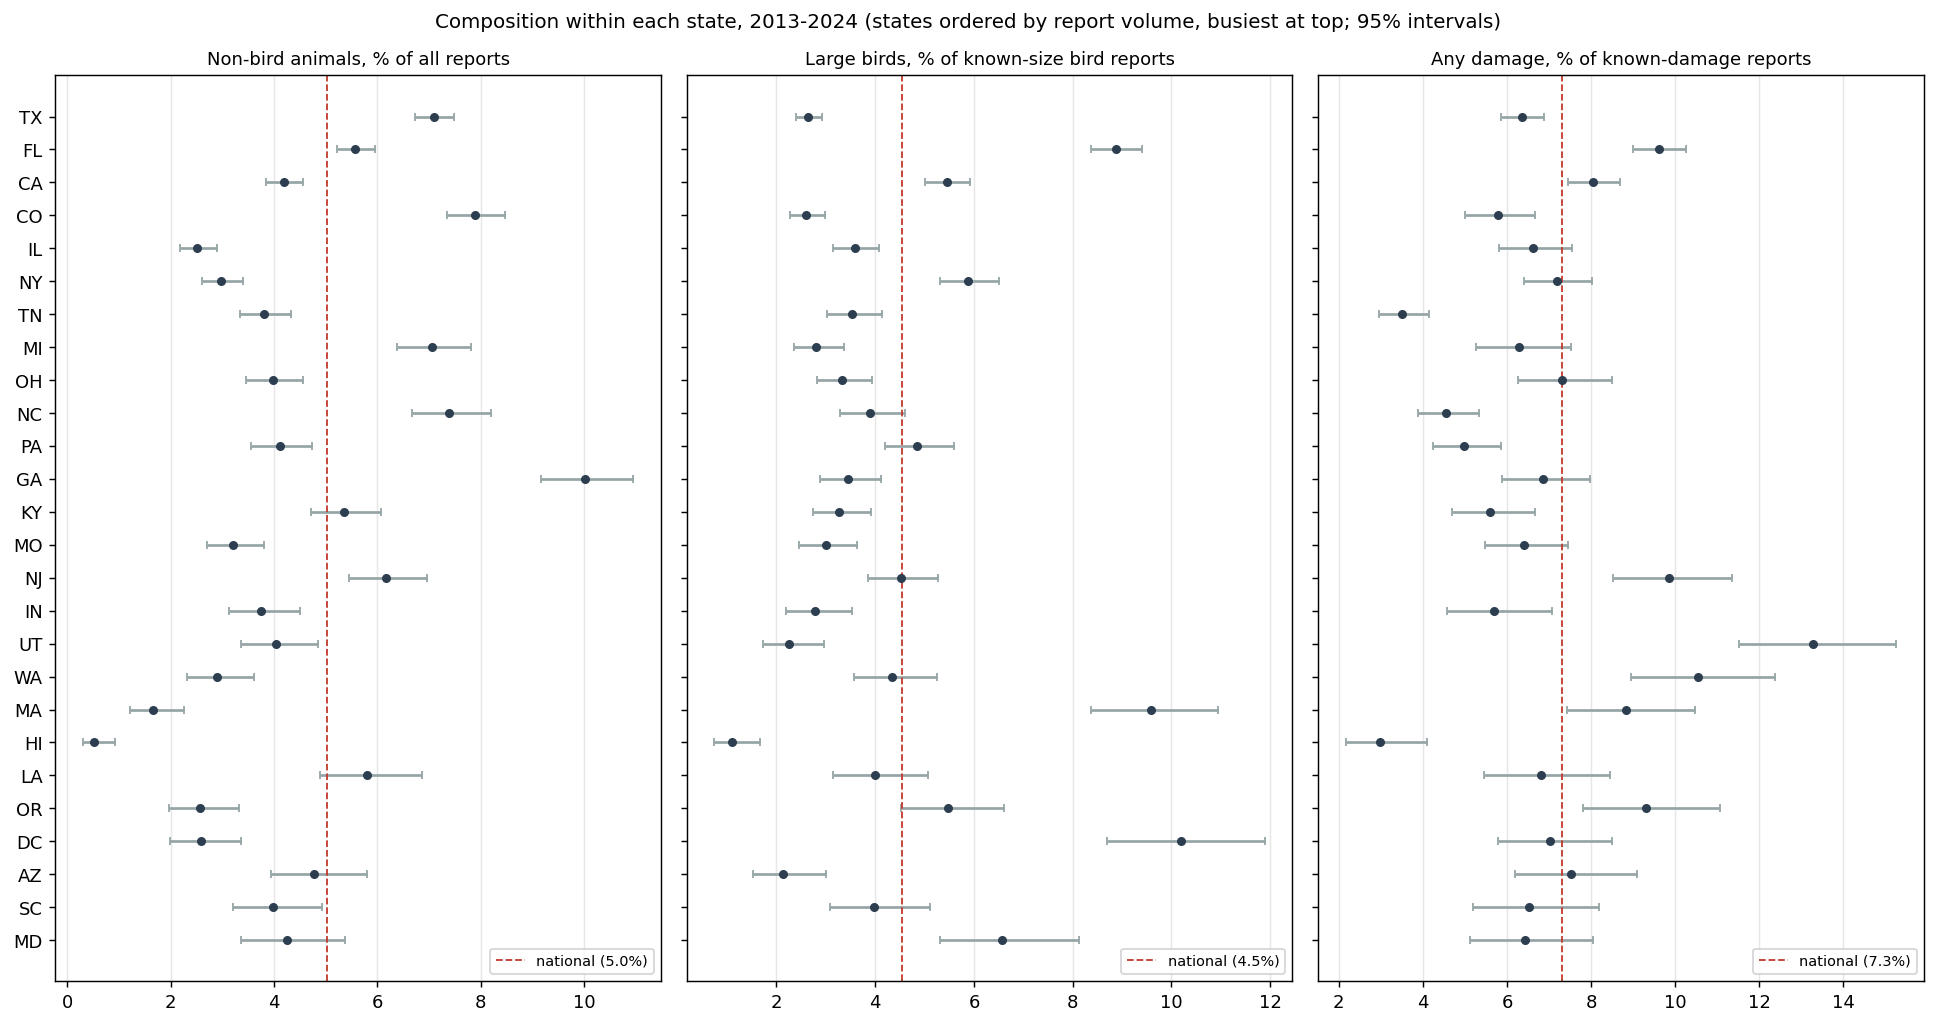

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 8), sharey=True)
ypos = np.arange(len(q))[::-1]
panels = [('nonbird', 'Non-bird animals, % of all reports'),
          ('large', 'Large birds, % of known-size bird reports'),
          ('dmg', 'Any damage, % of known-damage reports')]
for ax, (name, title), (_, _, _, nat) in zip(axes, panels, MEASURES):
    col, lo, hi = f'{name}_pct', f'{name}_lo', f'{name}_hi'
    ax.errorbar(q[col], ypos, xerr=[q[col] - q[lo], q[hi] - q[col]], fmt='o', color='#2c3e50', ecolor='#95a5a6',
                capsize=2, markersize=4)
    ax.axvline(nat, color='#c0392b', linestyle='--', linewidth=1, label=f'national ({nat:.1f}%)')
    ax.set_title(title, fontsize=10)
    ax.set_yticks(ypos)
    ax.set_yticklabels(q.index)
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(alpha=0.3, axis='x')
fig.suptitle('Composition within each state, 2013-2024 (states ordered by report volume, busiest at top; 95% intervals)', fontsize=11)
fig.tight_layout()


Read directly from the chart and the table above it:

- **Non-bird share** (national 5.0%): from 0.5% in Hawaii to 10.0% in Georgia. 7 states sit entirely above the
  national share, 15 entirely below, and 4 overlap it.
- **Large-bird share** (national 4.5%): from 1.1% in Hawaii to 10.2% in DC. Florida (8.9%) and Massachusetts
  (9.6%) are far above Texas and Colorado (both 2.6%), with intervals that don't come close to overlapping.
  6 states entirely above, 13 entirely below, 7 overlapping.
- **Any-damage share** (national 7.3%): from 3.0% in Hawaii to 13.3% in Utah. Tennessee (3.5%) is the next
  lowest after Hawaii; Utah (13.3%), Washington (10.5%), New Jersey (9.8%) and Florida (9.6%) are the four
  highest. 7 above, 8 below, 11 overlapping.

So composition differs between states by far more than sampling noise, and because these are shares within a
state, it is not "a state that's just proportionally busier." Hawaii is lowest on all three measures. That is
a description. What the data can't say is *why* — the next cells test two candidate explanations that would
make these differences about reporting rather than about what hits aircraft.

In [13]:
# A "state" is often mostly one airport. How much of each state's reports does its single largest airport supply?
ap_n = w.groupby(['STATE', 'AIRPORT_ID']).size().rename('n').reset_index()
lead = ap_n.sort_values('n', ascending=False).drop_duplicates('STATE').set_index('STATE')
q['lead_airport'] = lead['AIRPORT_ID']
q['lead_share'] = lead['n'] / g['rows'] * 100
print(f"single largest airport as a share of the state's reports, {len(q)} states: "
      f"median {q['lead_share'].median():.1f}%, range {q['lead_share'].min():.1f}% ({q['lead_share'].idxmin()}) to "
      f"{q['lead_share'].max():.1f}% ({q['lead_share'].idxmax()})")
print(q.sort_values('lead_share', ascending=False)[['lead_airport', 'lead_share']].head(8).round(1).T.to_string())
print()
print('the states at the two ends of the any-damage ranking: is it the lead airport, or the rest of the state?')
ends = list(q['dmg_pct'].sort_values().index[:2]) + list(q['dmg_pct'].sort_values().index[-2:])
for st in ends:
    s = w[w['STATE'] == st]
    la = q.loc[st, 'lead_airport']
    a, b = s[s['AIRPORT_ID'] == la], s[s['AIRPORT_ID'] != la]
    print(f"  {st}: state {q.loc[st, 'dmg_pct']:.1f}% | lead airport {la} {a['any_damage'].mean() * 100:.1f}% (n={a['any_damage'].count():,}) "
          f"| rest of state {b['any_damage'].mean() * 100:.1f}% (n={b['any_damage'].count():,})")


single largest airport as a share of the state's reports, 26 states: median 45.3%, range 15.0% (FL) to 91.2% (UT)
STATE           UT    MD    CO    GA    MA    MI    OR    NC
lead_airport  KSLC  KBWI  KDEN  KATL  KBOS  KDTW  KPDX  KCLT
lead_share    91.2  84.8  73.3  69.0  62.2  57.1  54.8  52.4

the states at the two ends of the any-damage ranking: is it the lead airport, or the rest of the state?
  HI: state 3.0% | lead airport PHNL 4.3% (n=349) | rest of state 2.5% (n=856)
  TN: state 3.5% | lead airport KMEM 2.8% (n=1,992) | rest of state 4.3% (n=1,683)
  WA: state 10.5% | lead airport KSEA 7.9% (n=621) | rest of state 13.2% (n=612)
  UT: state 13.3% | lead airport KSLC 13.3% (n=1,117) | rest of state 12.8% (n=141)


In [14]:
# Is the state-to-state variation about what is struck, or about how reports get filed? Three lenses.
def rank_corr(a, b):
    return a.rank().corr(b.rank())          # Spearman = Pearson on ranks

# (a) restrict to reports tied to an identified flight
wf = w[~w['no_flight']]
gf = wf.groupby('STATE').agg(rows=('INDEX_NR', 'size'), nonbird=('nonbird', 'sum'),
                              n_size=('large', 'count'), large=('large', 'sum'),
                              n_dmg=('any_damage', 'count'), dmg=('any_damage', 'sum'))
gf = gf.loc[gf.index.intersection(q.index)]
gf = gf[(gf['n_size'] >= 300) & (gf['n_dmg'] >= 300)]
gf['nonbird_pct'] = gf['nonbird'] / gf['rows'] * 100
gf['large_pct'] = gf['large'] / gf['n_size'] * 100
gf['dmg_pct'] = gf['dmg'] / gf['n_dmg'] * 100
print(f'flight-attached reports only (floor 300 known-value rows): {len(gf)} of {len(q)} states keep enough rows')
print(f"  national non-bird share {wf['nonbird'].mean() * 100:.1f}%, Large share {wf['large'].mean() * 100:.1f}%, "
      f"any-damage share {wf['any_damage'].mean() * 100:.1f}%  (all reports: {w['nonbird'].mean() * 100:.1f}%, "
      f"{w['large'].mean() * 100:.1f}%, {w['any_damage'].mean() * 100:.1f}%)")
for name, col in [('non-bird share', 'nonbird_pct'), ('Large share', 'large_pct'), ('any-damage share', 'dmg_pct')]:
    print(f"  {name}: all reports vs flight-attached, rank correlation across {len(gf)} states = {rank_corr(q.loc[gf.index, col], gf[col]):.2f}; "
          f"range all {q.loc[gf.index, col].min():.1f}-{q.loc[gf.index, col].max():.1f}%, flight-attached {gf[col].min():.1f}-{gf[col].max():.1f}%")

# (b) how much do states differ in how reports get filed?
print()
print(f'how reports get filed varies a lot by state ({len(q)} states):')
for name, col in [('no flight number', 'pct_no_flight'), ('species unidentified', 'pct_unidentified'), ('damage status known', 'pct_damage_known')]:
    print(f'  % with {name:22s}: {q[col].min():.1f}% ({q[col].idxmin()}) to {q[col].max():.1f}% ({q[col].idxmax()})')

# (c) are the composition measures simply tracking those filing differences? (and how big must a correlation be to mean anything?)
rng = np.random.default_rng(0)
x = np.arange(len(q))
null = [abs(np.corrcoef(x, rng.permutation(len(q)))[0, 1]) for _ in range(20000)]
print()
print(f'with {len(q)} states, a rank correlation must exceed about {np.quantile(null, 0.95):.2f} in size to be distinguishable from zero '
      f'(95th percentile of 20,000 shuffles)')
print('rank correlations across states (Spearman):')
for m_name, m in [('non-bird share', 'nonbird_pct'), ('Large share', 'large_pct'), ('any-damage share', 'dmg_pct')]:
    for r_name, r in [('% no flight number', 'pct_no_flight'), ('% species unidentified', 'pct_unidentified'),
                      ('% damage status known', 'pct_damage_known')]:
        print(f'  {m_name:16s} vs {r_name:23s}: {rank_corr(q[m], q[r]):+.2f}')


flight-attached reports only (floor 300 known-value rows): 26 of 26 states keep enough rows
  national non-bird share 2.5%, Large share 5.1%, any-damage share 5.3%  (all reports: 5.0%, 4.5%, 7.3%)
  non-bird share: all reports vs flight-attached, rank correlation across 26 states = 0.58; range all 0.5-10.0%, flight-attached 0.1-5.4%
  Large share: all reports vs flight-attached, rank correlation across 26 states = 0.89; range all 1.1-10.2%, flight-attached 1.4-10.7%
  any-damage share: all reports vs flight-attached, rank correlation across 26 states = 0.88; range all 3.0-13.3%, flight-attached 2.8-11.6%

how reports get filed varies a lot by state (26 states):
  % with no flight number      : 29.2% (DC) to 63.3% (CO)
  % with species unidentified  : 16.2% (CO) to 56.4% (DC)
  % with damage status known   : 34.3% (CO) to 71.0% (NC)

with 26 states, a rank correlation must exceed about 0.39 in size to be distinguishable from zero (95th percentile of 20,000 shuffles)
rank correlations ac

**1. A state is often mostly one airport.** The largest airport supplies a median of 45.3% of a state's reports
and as much as 91.2% (Utah: Salt Lake City). A state's composition is therefore frequently one airport's
composition, with its reporting habits, aircraft mix and local habitat bundled together. The extremes of the
damage ranking aren't simply that lead airport, though: Utah's 13.3% holds for Salt Lake City (13.3%) and
for the rest of the state (12.8%, but on only 141 known-damage rows); Tennessee's low share holds for Memphis
(2.8%) and the rest of the state (4.3%); and Washington's rest-of-state figure (13.2%) is *higher* than
Seattle's (7.9%).

**2. Reporting practice.** States differ enormously in how reports get filed: the share with no flight number
runs from 29.2% (DC) to 63.3% (Colorado), the share with the species unidentified from 16.2% (Colorado) to
56.4% (DC), and the share with a known damage status from 34.3% (Colorado) to 71.0% (North Carolina). Two
checks follow.

- *Dropping reports with no flight number* leaves the large-bird and damage orderings largely intact (rank
  correlation with the all-reports ordering 0.89 and 0.88) but not the non-bird share (0.58), and it halves the
  national non-bird share (5.0% to 2.5%). Non-bird reports are disproportionately ones with no flight
  attached, so a state's non-bird share is substantially a feature of how it files reports. The large-bird
  and damage patterns don't depend on those reports.
- *Do the composition measures simply track filing practice?* With 26 states a rank correlation has to exceed
  about 0.39 in size to be distinguishable from zero. The non-bird and damage shares don't — all six of
  their correlations with the three filing measures lie between -0.27 and +0.24. The large-bird share does:
  it is lower where more reports lack a flight number (-0.47) and higher where more reports have a known
  damage status (+0.44). States that document their reports fully also show more large birds, which fits
  large-bird strikes being likelier to get a complete report, or a shared underlying cause; this dataset
  can't separate the two.

In [15]:
# The same three measures at the level of FAA regions: far fewer, much larger units, so no single airport dominates.
gr = w.groupby('FAAREGION').agg(
    rows=('INDEX_NR', 'size'), nonbird=('nonbird', 'sum'),
    n_size=('large', 'count'), large=('large', 'sum'),
    n_dmg=('any_damage', 'count'), dmg=('any_damage', 'sum'))
gr['nonbird_%'] = gr['nonbird'] / gr['rows'] * 100
gr['large_%'] = gr['large'] / gr['n_size'] * 100
gr['damage_%'] = gr['dmg'] / gr['n_dmg'] * 100
lead_r = w.groupby(['FAAREGION', 'AIRPORT_ID']).size().rename('n').reset_index().sort_values('n', ascending=False).drop_duplicates('FAAREGION').set_index('FAAREGION')
gr['lead_airport_share_%'] = lead_r['n'] / gr['rows'] * 100
print(gr[['rows', 'nonbird_%', 'n_size', 'large_%', 'n_dmg', 'damage_%', 'lead_airport_share_%']].sort_values('rows', ascending=False).round(1).to_string())
print()
for col in ['nonbird_%', 'large_%', 'damage_%']:
    print(f'{col:10s}: regions {gr[col].min():.1f}% ({gr[col].idxmin()}) to {gr[col].max():.1f}% ({gr[col].idxmax()})')
print()
big = gr.drop(index='AAL')          # Alaska's region is small (752 reports) and is the outlier on two measures
for col in ['nonbird_%', 'large_%', 'damage_%']:
    print(f'excluding AAL -- {col}: regions {big[col].min():.1f}% ({big[col].idxmin()}) to {big[col].max():.1f}% ({big[col].idxmax()})')
print(f"largest single-airport share of any region's reports: {gr['lead_airport_share_%'].max():.1f}% ({gr['lead_airport_share_%'].idxmax()})")


            rows  nonbird_%  n_size  large_%  n_dmg  damage_%  lead_airport_share_%
FAAREGION                                                                          
ASO        38084        5.9   29039      5.6  21983       6.9                   7.8
AGL        25640        4.1   21542      3.7  10963       7.5                  14.5
ASW        23015        6.9   17336      2.9  11740       6.5                  20.4
AEA        21271        4.1   17275      5.9  12138       7.4                  12.6
ANM        17937        5.5   15362      3.4   7441       8.7                  36.2
AWP        17072        3.8   13681      4.4  10445       7.3                  10.7
ACE         7314        3.6    6094      3.3   4277       7.1                  23.3
ANE         5638        3.2    4866      6.9   2871       7.8                  26.0
AAL          752        4.0     656     15.5    431      15.8                  29.5

nonbird_% : regions 3.2% (ANE) to 6.9% (ASW)
large_%   : regions 2.9% (ASW)

**At the level of FAA regions** — nine units, far larger, with no single airport supplying more than 36.2% of any
region's reports — the spread is much narrower than across states. Excluding Alaska, whose region is small
(752 reports) and stands out on two measures (15.5% large birds, 15.8% damage), the regions run from 3.2% to
6.9% non-bird, 2.9% to 6.9% large birds, and 6.5% to 8.7% damage. The state extremes (Hawaii and DC for large
birds, Hawaii and Utah for damage) are smaller, more airport-dominated units; averaging over many airports
pulls them toward the middle, so the state-level range overstates how much *regions* differ in what is struck.
That is a general feature of aggregation, not a finding about wildlife.

**What this section does and doesn't establish.** Composition does differ by place beyond sampling noise — the
"no strong regional difference, strikes just concentrate where flights do" outcome the question allowed for is
*not* what the data show at the state level. But three things stop those differences from being read as
differences in what hits aircraft: a state is often essentially one airport; filing practice varies enormously
and tracks the large-bird share; and the spread shrinks at region level. The defensible statement is that
reports from different places have measurably different make-ups, and this dataset can't apportion the
difference between wildlife, aircraft mix, and reporting.

## 4. A spatial view — and what the coordinates are

The natural expectation is that roughly 300,000 `LATITUDE`/`LONGITUDE` points will trace a recognisable US
outline, and that strikes will be seen clustering at airports rather than along flight paths. The first half
is true. The second needs care, because of what these coordinates are: they are not strike locations. The
FAA's field list names them `AIRPORT_LATITUDE` and `AIRPORT_LONGITUDE`, and describes `AIRPORT_ID` as the
airport identifier for the location of a strike *whether it was on or off the airport* — so even a strike off
the airfield is filed under an airport. The check below tests the coordinates directly rather than relying on
the names.

In [16]:
loc = d[d['LATITUDE'].notna() & d['LONGITUDE'].notna()]
n_pairs = loc.groupby(['LATITUDE', 'LONGITUDE']).ngroups
n_airports = loc['AIRPORT_ID'].nunique()
per_airport_pairs = loc.groupby('AIRPORT_ID').apply(lambda g: g[['LATITUDE', 'LONGITUDE']].drop_duplicates().shape[0],
                                                   include_groups=False)
shared = loc.groupby(['LATITUDE', 'LONGITUDE'])['AIRPORT_ID'].nunique()
print(f'rows with coordinates: {len(loc):,}')
print(f'distinct (LATITUDE, LONGITUDE) pairs: {n_pairs:,}   distinct AIRPORT_ID: {n_airports:,}')
print(f'airports with exactly one coordinate pair: {(per_airport_pairs == 1).sum():,} of {len(per_airport_pairs):,}')
print(f'coordinate pairs shared by more than one AIRPORT_ID: {(shared > 1).sum()}')

box = loc['LONGITUDE'].between(-125, -66.5) & loc['LATITUDE'].between(24.5, 49.5)
print()
print(f'inside the contiguous-US box: {box.sum():,} rows ({box.mean() * 100:.1f}%) at {loc.loc[box, "AIRPORT_ID"].nunique():,} airports')
print(f'outside it: {(~box).sum():,} rows at {loc.loc[~box, "AIRPORT_ID"].nunique():,} airports; by STATE: '
      f'{loc.loc[~box, "STATE"].value_counts().head(8).to_dict()}')


rows with coordinates: 297,511
distinct (LATITUDE, LONGITUDE) pairs: 2,765   distinct AIRPORT_ID: 2,767
airports with exactly one coordinate pair: 2,765 of 2,767
coordinate pairs shared by more than one AIRPORT_ID: 4

inside the contiguous-US box: 283,134 rows (95.2%) at 2,328 airports
outside it: 14,377 rows at 439 airports; by STATE: {'HI': 5669, 'FN': 5015, 'AK': 1673, 'PR': 768, 'VI': 396, 'GU': 336, 'MP': 238, 'UM': 118}


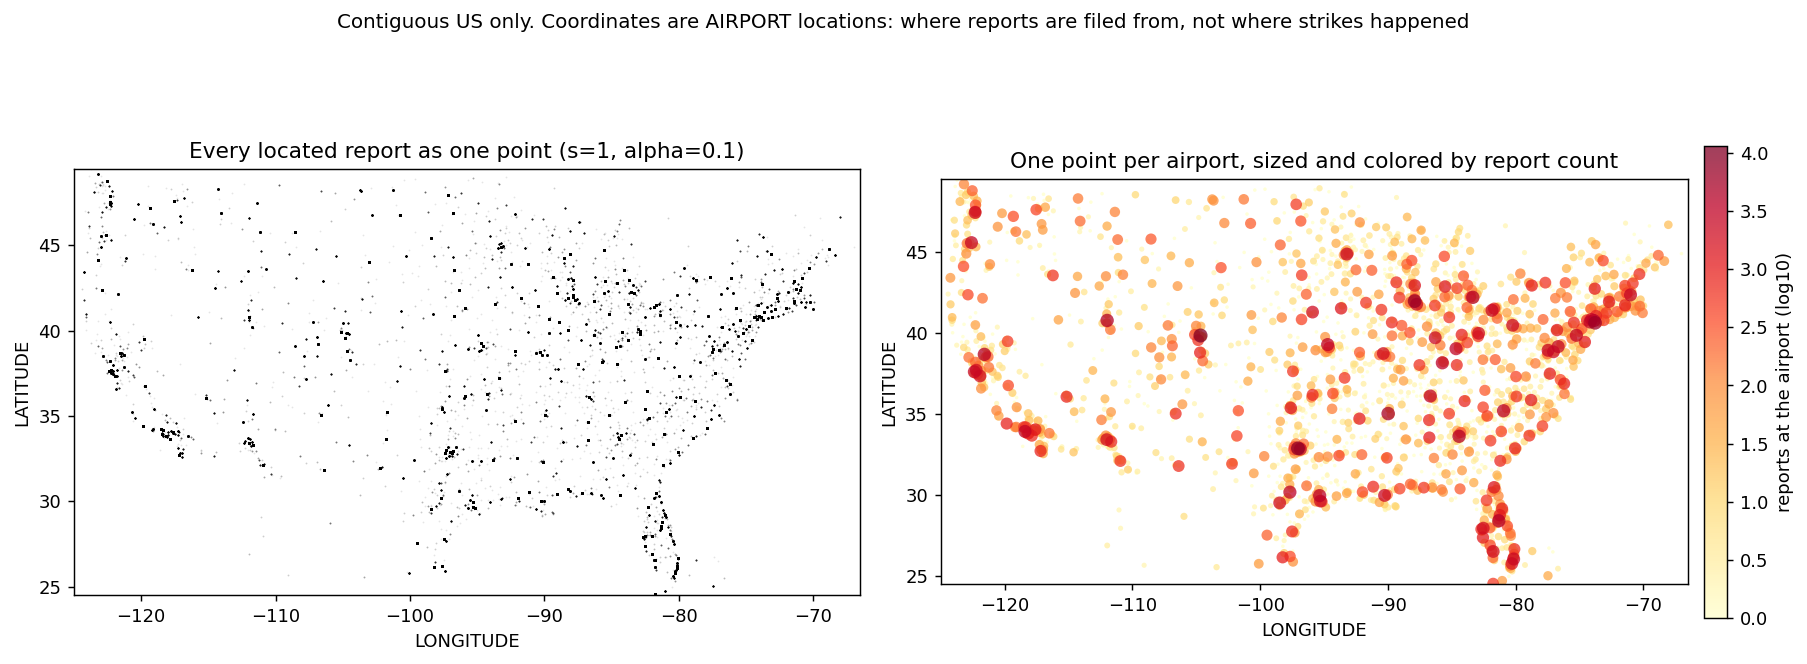

In [17]:
pts = loc.groupby(['LATITUDE', 'LONGITUDE']).size().rename('reports').reset_index().sort_values('reports')
aspect = 1 / np.cos(np.radians(38))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))

ax = axes[0]
ax.scatter(loc['LONGITUDE'], loc['LATITUDE'], s=1, alpha=0.1, color='black', linewidths=0)
ax.set_title('Every located report as one point (s=1, alpha=0.1)')

ax = axes[1]
sc = ax.scatter(pts['LONGITUDE'], pts['LATITUDE'], s=4 + 14 * np.log10(pts['reports']), c=np.log10(pts['reports']),
                cmap='YlOrRd', alpha=0.75, linewidths=0)
cb = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.02)
cb.set_label('reports at the airport (log10)')
ax.set_title('One point per airport, sized and colored by report count')

for ax in axes:
    ax.set_xlim(-125, -66.5); ax.set_ylim(24.5, 49.5)
    ax.set_aspect(aspect)
    ax.set_xlabel('LONGITUDE'); ax.set_ylabel('LATITUDE')
fig.suptitle('Contiguous US only. Coordinates are AIRPORT locations: where reports are filed from, not where strikes happened', fontsize=11)
fig.tight_layout()


The check settles it: 2,765 distinct coordinate pairs for 2,767 airports, and 2,765 of those airports have
exactly one pair. Every report is placed at its airport's coordinates, so:

- **"Strikes cluster at airports" is true by construction, not evidence.** The map can't distinguish strikes
  happening at airports from the dataset assigning airport coordinates to every report. (En-route strikes —
  1.8% of rows — have no coordinates at all; they sit in the unplaced `ZZZZ` group.)
- **There is no within-airport or along-flight-path information to map.** A report at Denver is a point exactly
  on Denver, wherever the strike happened.
- **The plain scatter saturates.** At alpha 0.1 a couple of dozen stacked points already look nearly solid, and
  a busy airport stacks thousands, so every airport with more than a few dozen reports looks equally black.
  The left panel shows *where airports with reports are*, not how many reports each has. The right panel —
  one point per airport, sized and colored by log report count — is the version that carries information.

What the map does show: 283,134 of the 297,511 located rows (95.2%) fall inside the contiguous-US box shown,
at 2,328 airports; the other 14,377 rows (439 airports) are Hawaii (5,669), foreign airports (5,015), Alaska
(1,673), and the territories. Within the box, density follows where airports and traffic are — the Northeast
corridor, the Great Lakes, California, Florida and the Texas cities stand out — which is section 1's ranking
drawn on a map. It adds geography, not new information about how likely strikes are.

## 5. Future work — joining outside operations data (not attempted here)

The volume question in section 2 can be answered properly for many airports and years, but it is a project of
its own.

**What exists.** The FAA's Terminal Area Forecast (TAF) provides historical airport activity — 1990 through
2025 in the current edition, the same span as this dataset — by individual airport, state or FAA region, on a
fiscal-year basis. Operations at towered airports are controller counts; at non-FAA airports the TAF's counts
are estimates.

**What it would take.**

1. **A join key.** `AIRPORT_ID` here is ICAO-style (`KDEN`); the TAF tables are keyed by FAA location
   identifiers (`DEN`). Stripping a `K` handles most of the contiguous US and fails for Alaska, Hawaii, the
   territories, and non-standard identifiers like `5PA5`.
2. **Period alignment.** Fiscal-year operations against this dataset's dates — done by hand for four airports
   above, it would need doing systematically.
3. **Rows that can't be placed.** 13.4% of rows have no real airport (section 0) and can't be assigned a
   denominator at all; en-route strikes are not airport-based by nature.
4. **Coverage differences.** Many airports in this dataset are small non-towered fields whose operations are
   estimates, not counts.
5. **The denominator still isn't exposure.** All operations (general aviation and military included) rather
   than the aircraft mostly struck, and nothing about time of day, season, or runway mix.
6. **It would still be reports per operation,** mixing wildlife, aircraft mix and reporting diligence: a better
   comparison than a raw count, not a risk measure on its own.

**Why not here.** A second data source, a join key to resolve, and its own quality questions don't fit
alongside everything else in this session. A quick same-dataset proxy — counting distinct operators or flights
per airport — would be built from the same reporting the counts come from and would inherit its biases, so it
would look like a solution without being one.

## Summary

**What the geographic fields cover.** 86.6% of 1990-2025 rows are at a real airport; 13.4% (46,047) are not,
almost all of them `UNKNOWN`, and en-route strikes sit in that unplaced group. "State" means the airport's
state.

**Raw concentration (reports, not risk).** Five states hold 38.3% of state-coded rows; the top 10 airports
hold 20.6% of rows at real airports and the top 50 hold 55.4%, while the median airport has 3 reports.

**The volume confound, with real numbers.** Chicago O'Hare has more reports than Detroit in each of FY2022-FY2025
while Detroit's per-operation rate is 1.4-1.9 times O'Hare's; Denver leads on both measures. The adjustment can
reverse or reinforce a raw ranking, and the per-operation rate is still not a risk measure.

**Composition within states (2013-2024).** Large-bird share, non-bird share and damage share all differ between
states by far more than sampling noise (large birds 1.1% to 10.2%, damage 3.0% to 13.3%). But a state is often
mostly one airport (median 45.3% of its reports), filing practice varies widely and tracks the large-bird
share, and the spread shrinks at region level. The honest reading: reports from different places differ in
make-up, and this dataset can't say whether that is wildlife, aircraft or reporting.

**The map.** Coordinates are airport locations (2,765 pairs for 2,767 airports), so "strikes cluster at
airports" is true by construction and a plain scatter saturates; a per-airport bubble map is the informative
version.

**Corrections found along the way.** Notebook 01: 83 rows with a named airport but a missing location field,
not zero. Notebook 04: `SIZE` is filled in for non-birds (so "bird size" needed birds only), the FAA species code
exposed 24 non-bird values the keyword rules had missed, and reading the whole default bucket found 8 group
names.

**Future work.** Join the FAA TAF operations data (section 5).

**Next:** the project's remaining phases — SQL analysis, validation of the strongest findings, and the
written report.